<a href="https://colab.research.google.com/github/Himanshu-kroy/diabetes-prediction-ml/blob/main/Diabetes_Prediction_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("File:", filename)

Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv
Dataset uploaded successfully!
File: pima-indians-diabetes.csv


In [4]:
print("First 5 rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:


,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0



Dataset Shape:
(767, 9)

Column Names:
['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   6       767 non-null    int64  
 1   148     767 non-null    int64  
 2   72      767 non-null    int64  
 3   35      767 non-null    int64  
 4   0       767 non-null    int64  
 5   33.6    767 non-null    float64
 6   0.627   767 non-null    float64
 7   50      767 non-null    int64  
 8   1       767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing Values:
6        0
148      0
72       0
35       0
0        0
33.6     0
0.627    0
50       0
1        0
dtype: int64


In [5]:

# Correct column names
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Reload dataset without treating first row as headers
df = pd.read_csv(filename, header=None, names=columns)

print("Dataset loaded correctly!")
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())


Dataset loaded correctly!

Dataset Shape: (768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First 5 Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

print("\nTarget Distribution:")
print(df['Outcome'].value_counts())


Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome             

In [7]:

# Columns where zero represents missing measurements
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Replace zero values with NaN
df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("Invalid zero values handled successfully!")

print("\nMissing values after processing:")
print(df.isnull().sum())


Invalid zero values handled successfully!

Missing values after processing:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [8]:

# Input features
X = df.drop('Outcome', axis=1)

# Target variable
y = df['Outcome']

print("Features and target separated!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features and target separated!
Features shape: (768, 8)
Target shape: (768,)


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=200,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Dataset split successfully!
Training records: 568
Testing records: 200


In [10]:

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [11]:

y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])


Predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 0 0 1 0 0]


In [12]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Extract values
tn, fp, fn, tp = cm.ravel()

print("\nTrue Positive (TP):", tp)
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)


Confusion Matrix:
[[111  19]
 [ 33  37]]

True Positive (TP): 37
True Negative (TN): 111
False Positive (FP): 19
False Negative (FN): 33


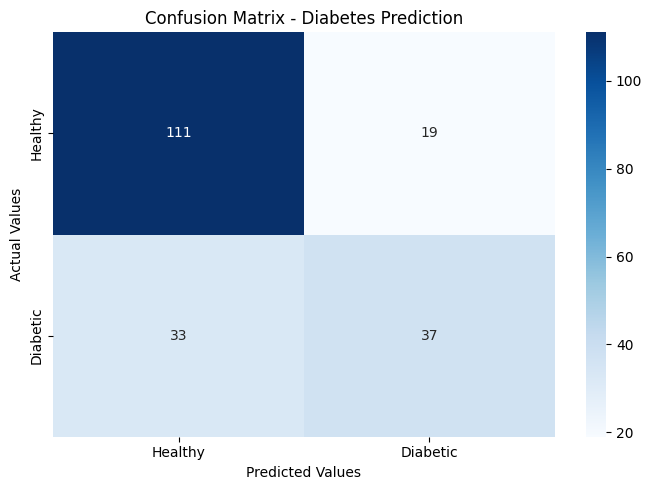

In [13]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Healthy', 'Diabetic'],
    yticklabels=['Healthy', 'Diabetic']
)

plt.title('Confusion Matrix - Diabetes Prediction')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()


In [14]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")


MODEL EVALUATION RESULTS
------------------------
Accuracy: 74.0 %
Precision: 66.07 %
Recall: 52.86 %
F1-Score: 58.73 %


In [15]:

print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Healthy', 'Diabetic'],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

     Healthy       0.77      0.85      0.81       130
    Diabetic       0.66      0.53      0.59        70

    accuracy                           0.74       200
   macro avg       0.72      0.69      0.70       200
weighted avg       0.73      0.74      0.73       200



In [16]:

results = pd.DataFrame({
    'Evaluation Metric': [
        'True Positive (TP)',
        'True Negative (TN)',
        'False Positive (FP)',
        'False Negative (FN)',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Result': [
        tp,
        tn,
        fp,
        fn,
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2)
    ]
})

display(results)


,Evaluation Metric,Result
0,True Positive (TP),37.00
1,True Negative (TN),111.00
2,False Positive (FP),19.00
3,False Negative (FN),33.00
4,Accuracy,74.00
5,Precision,66.07
6,Recall,52.86
7,F1-Score,58.73


In [17]:

# Save evaluation metrics
results.to_csv(
    'diabetes_evaluation_results.csv',
    index=False
)

# Save predictions
prediction_results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

prediction_results.to_csv(
    'diabetes_predictions.csv',
    index=False
)

print("All results saved successfully!")


All results saved successfully!


In [18]:

files.download('confusion_matrix.png')

files.download('diabetes_evaluation_results.csv')

files.download('diabetes_predictions.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>